# Notebook 06: Data Preparatie (v3)

### Inladen
---
1. Libraries en paths inladen
---

In [1]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd().parent / "locatie_data"
OUTPUT_DIR = Path.cwd().parent / "prepared_data"

2. Carport- en huisdata inladen
---

In [2]:
df_huis = pd.read_parquet(DATA_DIR / "huis788.parquet")
df_carport = pd.read_parquet(DATA_DIR / "carport.parquet")
df_huis = df_huis.sort_values(["timestamp", "ENAME"]).reset_index(drop=True)
df_carport = df_carport.sort_values(["timestamp", "ENAME"]).reset_index(drop=True)

In [3]:
print("Huis:", df_huis.shape, df_huis["timestamp"].min(), "t/m", df_huis["timestamp"].max())
print("Carport:", df_carport.shape, df_carport["timestamp"].min(), "t/m", df_carport["timestamp"].max())

Huis: (3057890, 25) 2024-03-08 01:00:00+01:00 t/m 2026-09-10 01:55:00+02:00
Carport: (4888431, 25) 2024-03-08 01:00:00+01:00 t/m 2026-09-07 08:05:00+02:00


3. Namen van reeksen die door ons meegenomen worden in modelleren
---

In [4]:
TOTAALVERBRUIK_HUIS = "totaalverbruik-16eda211b788"
OMVORMER_HUIS = "omvormer-16eda211b788"
HOOFDMETER_HUIS = "hoofdmeter-16eda211b788"

TOTAALVERBRUIK_CARPORT = "totaalverbruik-e4393cd3dfdb"
ZONNEPANELEN_CARPORT = "zonnepanelen-e4393cd3dfdb"
HOOFDAANSLUITING_CARPORT = "hoofdaansluiting-e4393cd3dfdb"
ACCU_CARPORT = "victronaccu-e4393cd3dfdb"

4. Filteren op ENAME, CTYPE, CTYPEC en ETYPE
---
- Waarom? -> Door eerst context te selecteren wordt voorkomen dat een andere record bij POW terecht komt.
- Dezelfde timestamp zegt op zichzelf niks 

voor huis:
- Totaalverbruik -> consumption
- Omvormer -> generation
- Hoofdmeter -> supply

In [5]:
#Huis
huis_verbruik = df_huis[(df_huis["ENAME"] == TOTAALVERBRUIK_HUIS) &
                        (df_huis["CTYPE"] == "electricity") &
                        (df_huis["CTYPEC"] == "consumption") &
                        (df_huis["ETYPE"] == "powermeter")].copy()

huis_opwekking = df_huis[(df_huis["ENAME"] == OMVORMER_HUIS) &
                         (df_huis["CTYPE"] == "electricity") &
                         (df_huis["CTYPEC"] == "generation") & (df_huis["ETYPE"] == "solarpanel")].copy()

huis_supply = df_huis[(df_huis["ENAME"] == HOOFDMETER_HUIS) &
                      (df_huis["CTYPE"] == "electricity") &
                      (df_huis["CTYPEC"] == "supply") &
                      (df_huis["ETYPE"] == "powermeter")].copy()

voor carport:
- Totaalverbruik -> consumption
- Zonnepanelen -> generation
- Hoofdaansluiting -> supply
- Accu -> storage

In [6]:
#Carport
carport_verbruik = df_carport[(df_carport["ENAME"] == TOTAALVERBRUIK_CARPORT) &
                              (df_carport["CTYPE"] == "electricity") &
                              (df_carport["CTYPEC"] == "consumption") &
                              (df_carport["ETYPE"] == "powermeter")].copy()

carport_opwekking = df_carport[(df_carport["ENAME"] == ZONNEPANELEN_CARPORT) &
                               (df_carport["CTYPE"] == "electricity") &
                               (df_carport["CTYPEC"] == "generation") &
                               (df_carport["ETYPE"] == "solarpanel")].copy()

carport_supply = df_carport[(df_carport["ENAME"] == HOOFDAANSLUITING_CARPORT) &
                            (df_carport["CTYPE"] == "electricity") &
                            (df_carport["CTYPEC"] == "supply") &
                            (df_carport["ETYPE"] == "powermeter")].copy()

carport_accu = df_carport[(df_carport["ENAME"] == ACCU_CARPORT) &
                          (df_carport["CTYPE"] == "electricity") &
                          (df_carport["CTYPEC"] == "storage") &
                          (df_carport["ETYPE"] == "battery")].copy()

In [7]:
print("Huis verbruik:", len(huis_verbruik))
print("Huis opwekking:", len(huis_opwekking))
print("Huis supply:", len(huis_supply))
print("Carport verbruik:", len(carport_verbruik))
print("Carport opwekking:", len(carport_opwekking))
print("Carport supply:", len(carport_supply))
print("Carport accu:", len(carport_accu))

Huis verbruik: 228500
Huis opwekking: 200703
Huis supply: 188250
Carport verbruik: 222914
Carport opwekking: 207288
Carport supply: 219821
Carport accu: 130719


### Preparatie
---
1. Tijd van dubbele pow waarden met dezelfde contextvariabelen vastleggen en deze records verwijderen (zowel huis als carport)
---

In [8]:
conflict_tijd = pd.Timestamp("2024-10-05 20:10:00", tz="Europe/Amsterdam")

In [9]:
huis_verbruik_pow = huis_verbruik[huis_verbruik["POW"].notna() & (huis_verbruik["timestamp"] != conflict_tijd)].copy()
huis_opwekking_pow = huis_opwekking[huis_opwekking["POW"].notna()].copy()
huis_supply_pow = huis_supply[huis_supply["POW"].notna() & (huis_supply["timestamp"] != conflict_tijd)].copy()

In [10]:
carport_verbruik_pow = carport_verbruik[carport_verbruik["POW"].notna() & (carport_verbruik["timestamp"] != conflict_tijd)].copy()
carport_opwekking_pow = carport_opwekking[carport_opwekking["POW"].notna() & (carport_opwekking["timestamp"] != conflict_tijd)].copy()
carport_supply_pow = carport_supply[carport_supply["POW"].notna() & (carport_supply["timestamp"] != conflict_tijd)].copy()
carport_accu_pow = carport_accu[carport_accu["POW"].notna()].copy()

In [11]:
#Snelle check op POW uniekheid
assert huis_verbruik_pow["timestamp"].is_unique
assert huis_opwekking_pow["timestamp"].is_unique
assert huis_supply_pow["timestamp"].is_unique
assert carport_verbruik_pow["timestamp"].is_unique
assert carport_opwekking_pow["timestamp"].is_unique
assert carport_supply_pow["timestamp"].is_unique
assert carport_accu_pow["timestamp"].is_unique

2. 5 minuten-raster
---
- Maakt één rij per iedere 5 minuten zodat ontbrekende tijdstippen er wel in gaan staan.
- Waarom? -> Zo is voor het model te zien "waar" de data ontbreekt.

In [12]:
def maak_raster(df_context, df_pow, locatie, target_type):
    volledige_tijd = pd.date_range(start=df_context["timestamp"].min(), end=df_context["timestamp"].max(), freq="5min")

    raster = pd.DataFrame({"timestamp": volledige_tijd})
    raster = raster.merge(df_pow[["timestamp", "POW"]], on="timestamp", how="left")
    raster = raster.rename(columns={"POW": "pow_w"})

    raster["location"] = locatie
    raster["target_type"] = target_type
    raster["is_observed"] = raster["pow_w"].notna()
    raster["is_conflict"] = False

    return raster

In [13]:
huis_verbruik_raster = maak_raster(huis_verbruik, huis_verbruik_pow, "huis", "consumption")
huis_opwekking_raster = maak_raster(huis_opwekking, huis_opwekking_pow, "huis", "generation")
huis_supply_raster = maak_raster(huis_supply, huis_supply_pow, "huis", "supply")

In [14]:
carport_verbruik_raster = maak_raster(carport_verbruik, carport_verbruik_pow, "carport", "consumption")
carport_opwekking_raster = maak_raster(carport_opwekking, carport_opwekking_pow, "carport", "generation")
carport_supply_raster = maak_raster(carport_supply, carport_supply_pow, "carport", "supply")
carport_accu_raster = maak_raster(carport_accu, carport_accu_pow, "carport", "storage")

3. Conflicten markeren
---

In [15]:
huis_verbruik_raster.loc[huis_verbruik_raster["timestamp"] == conflict_tijd, "is_conflict"] = True
huis_supply_raster.loc[huis_supply_raster["timestamp"] == conflict_tijd, "is_conflict"] = True
carport_verbruik_raster.loc[carport_verbruik_raster["timestamp"] == conflict_tijd, "is_conflict"] = True
carport_opwekking_raster.loc[carport_opwekking_raster["timestamp"] == conflict_tijd, "is_conflict"] = True
carport_supply_raster.loc[carport_supply_raster["timestamp"] == conflict_tijd, "is_conflict"] = True

4. Impute: gaten invullen per lengte

> Een **gat** is een reeks van één of meer ontbrekende 5-minuten punten achter elkaar. De lengte van het gat bepaalt welke methode gebruikt wordt
>
> Alleen gaten met een echte meting vóór én na het gat worden ingevuld. Gaten waar het conflict-tijdstip in valt blijven leeg
>
> **Alleen de train-data wordt ingevuld.** De data wordt eerst gesplitst in train, validatie en test (4.0). In validatie en test blijven de gaten leeg, zodat een model daar nooit gescoord wordt tegen een waarde die niet gemeten is

| Lengte gat | Methode |
|---|---|
| 5 t/m 15 minuten | Seasonal naive (4.3) |
| 20 t/m 60 minuten | Forward fill (4.4) |
| langer dan 60 minuten, nachtgat bij opwekking | 0 W (4.5) |
| langer dan 60 minuten, overig | niet invullen (4.6) |

**Aangepast na testen (v2) en na feedback (v3)**

> In de eerste versie van dit notebook (`06_Dataprep.ipynb`) waren de methodes gekozen op basis van de literatuur. Daarna zijn 8 methodes getest op zelf gemaakte gaten in `07_Impute_tests.ipynb`, en op basis daarvan zijn de keuzes aangepast

| Lengte gat | Eerst | Nu |
|---|---|---|
| 5 t/m 15 minuten | Lineair | Seasonal naive |
| 20 t/m 60 minuten | Kalman smoother | Forward fill |
| 65 minuten t/m 1 dag | LightGBM | niet invullen, behalve nachtgaten bij opwekking (0 W) |
| langer dan 1 dag | niet invullen | niet invullen |

> In v2 werd de hele reeks ingevuld en pas daarna gesplitst. In v3 is dat omgedraaid: eerst splitsen, daarna alleen train invullen. Bij het invullen van train worden ook geen metingen uit validatie of test gebruikt
>
> De keuzes volgen de test op de losse test-gaten (07, stap 3). In de rondes met 50 gaten per lengte (07, stap 4) scoorden lineair (5 minuten) en de Kalman smoother (30 minuten) gemiddeld lager dan de methodes die nu gekozen zijn

4.0 Eerst splitsen in train, validatie en test

> De vensters zijn voor alle modellen en alle vier de reeksen hetzelfde. Zo worden de modellen op precies dezelfde momenten vergeleken
>
> **Test**: 4 vensters, één per seizoen. Hier wordt alleen de eindscore op berekend
>
> **Validatie**: 4 vensters, elk direct vóór een testvenster in hetzelfde seizoen. Voor early stopping en het kiezen van instellingen
>
> **Stresstest**: het stuk direct na de uitval van april 2026. Een aparte test van hoe een model zich gedraagt als er weinig recente data is, telt niet mee in de eindscore
>
> **Train**: alle overige data
>
> De vensters zijn gekozen op periodes waar alle vier de reeksen (bijna) compleet zijn, zie de grafiek in 9.2 en de dekking in 9.5. Begin is inclusief, eind is exclusief

**Train ligt ook ná testvensters**

> Omdat de testvensters over het jaar verspreid liggen, bevat train ook data van na een testvenster. Een trainvoorbeeld mag daarom geen enkel punt uit validatie of test bevatten, ook niet als input. Dat regelt `train_origins` in `models/evaluatie.py`

In [16]:
VENSTERS = [
    #venster, set, start, eind
    ("zomer", "val", "2025-06-23", "2025-07-03"),
    ("zomer", "test", "2025-07-03", "2025-07-14"),
    ("herfst", "val", "2025-10-22", "2025-10-31"),
    ("herfst", "test", "2025-10-31", "2025-11-10"),
    ("winter", "val", "2026-01-13", "2026-01-23"),
    ("winter", "test", "2026-01-23", "2026-02-04"),
    ("lente", "val", "2026-03-16", "2026-03-26"),
    ("lente", "test", "2026-03-26", "2026-04-07"),
    ("na_uitval", "stresstest", "2026-04-25", "2026-05-08")]

vensters = pd.DataFrame(VENSTERS, columns=["venster", "set", "start", "eind"])
vensters["dagen"] = (pd.to_datetime(vensters["eind"]) - pd.to_datetime(vensters["start"])).dt.days
vensters["start"] = pd.to_datetime(vensters["start"]).dt.tz_localize("Europe/Amsterdam")
vensters["eind"] = pd.to_datetime(vensters["eind"]).dt.tz_localize("Europe/Amsterdam")

#Vensters mogen elkaar niet overlappen
gesorteerd = vensters.sort_values("start")
assert (gesorteerd["start"].iloc[1:].to_numpy() >= gesorteerd["eind"].iloc[:-1].to_numpy()).all()

vensters

,venster,set,start,eind,dagen
0,zomer,val,2025-06-23 00:00:00+02:00,2025-07-03 00:00:00+02:00,10
1,zomer,test,2025-07-03 00:00:00+02:00,2025-07-14 00:00:00+02:00,11
2,herfst,val,2025-10-22 00:00:00+02:00,2025-10-31 00:00:00+01:00,9
3,herfst,test,2025-10-31 00:00:00+01:00,2025-11-10 00:00:00+01:00,10
4,winter,val,2026-01-13 00:00:00+01:00,2026-01-23 00:00:00+01:00,10
5,winter,test,2026-01-23 00:00:00+01:00,2026-02-04 00:00:00+01:00,12
6,lente,val,2026-03-16 00:00:00+01:00,2026-03-26 00:00:00+01:00,10
7,lente,test,2026-03-26 00:00:00+01:00,2026-04-07 00:00:00+02:00,12
8,na_uitval,stresstest,2026-04-25 00:00:00+02:00,2026-05-08 00:00:00+02:00,13


In [17]:
def label_set(df):
    #Alles is train, behalve de tijdstippen binnen een validatie-, test- of stresstestvenster
    resultaat = df.copy()
    resultaat["set"] = "train"
    resultaat["venster"] = None

    for venster in vensters.itertuples():
        binnen = (resultaat["timestamp"] >= venster.start) & (resultaat["timestamp"] < venster.eind)
        resultaat.loc[binnen, "set"] = venster.set
        resultaat.loc[binnen, "venster"] = venster.venster

    return resultaat


huis_verbruik_raster = label_set(huis_verbruik_raster)
huis_opwekking_raster = label_set(huis_opwekking_raster)
huis_supply_raster = label_set(huis_supply_raster)
carport_verbruik_raster = label_set(carport_verbruik_raster)
carport_opwekking_raster = label_set(carport_opwekking_raster)
carport_supply_raster = label_set(carport_supply_raster)
carport_accu_raster = label_set(carport_accu_raster)

huis_verbruik_raster["set"].value_counts()

set
train         235872
test           12948
val            11244
stresstest      3744
Name: count, dtype: int64

4.1 Per ontbrekend punt bepalen hoe lang het gat is waar het in zit

In [18]:
def bepaal_gaten(df):
    resultaat = df.copy()

    #Elke reeks ontbrekende punten achter elkaar krijgt een eigen gat-nummer
    ontbreekt = resultaat["pow_w"].isna()
    gat_nummer = (ontbreekt != ontbreekt.shift()).cumsum()

    #Lengte van het gat in minuten (aantal punten x 5 minuten), 0 bij een echte meting
    resultaat["gat_minuten"] = ontbreekt.groupby(gat_nummer).transform("sum") * 5
    resultaat.loc[~ontbreekt, "gat_minuten"] = 0

    #Is er een meting vóór én na het gat?
    heeft_voor = resultaat["pow_w"].ffill().notna()
    heeft_na = resultaat["pow_w"].bfill().notna()
    resultaat["gat_ingesloten"] = ontbreekt & heeft_voor & heeft_na

    #Zit het conflict-tijdstip in dit gat?
    resultaat["gat_met_conflict"] = resultaat["is_conflict"].groupby(gat_nummer).transform("any") & ontbreekt

    return resultaat

4.2 Kolommen voor de ingevulde waarden aanmaken

In [19]:
def maak_impute_kolommen(df):
    #Alleen bij de eerste invulstap, latere stappen vullen hierop aan
    if "pow_imputed" not in df:
        df["pow_imputed"] = df["pow_w"]
        df["is_imputed"] = False
        df["impute_methode"] = None

    return df

4.3 Gaten van 5 tot en met 15 minuten: seasonal naive

> **Seasonal naive** betekent: het ontbrekende punt krijgt de waarde van **precies 24 uur eerder**. Ontbreekt die ook, dan 2 dagen eerder, enzovoort tot maximaal een week terug
>
> Er wordt alleen teruggekeken naar echte metingen, niet naar eerder ingevulde waarden. Is er in de hele week ervoor op dat tijdstip niets gemeten, dan blijft het punt leeg

**Waarom seasonal naive?**

> Het is de simpelste methode die het dagpatroon meeneemt: verbruik en opwekking volgen elke dag ongeveer hetzelfde ritme (Hyndman & Athanasopoulos)
>
> In de test op het losse test-gat van 1 tijdvak (07, 3.3) had seasonal naive de laagste fout van de 8 methodes: 0,0 W, tegen 1,1 W voor lineair

**Eerst: lineair**

> In de eerste versie werd hier een rechte lijn getrokken van de meting vóór het gat naar de meting ná het gat. Die keuze kwam uit de literatuur: Kaur & Gabrijelčič vonden lineair de beste methode bij hun kortste gaten, en Wang et al. geven aan dat lineair meestal gebruikt wordt voor korte periodes
>
> Na de eigen test in 07 is dit aangepast naar seasonal naive

> Bron: Hyndman & Athanasopoulos (2021), [Forecasting: Principles and Practice, 3e editie, hoofdstuk 5.2 Some simple forecasting methods](https://otexts.com/fpp3/simple-methods.html)
>
> Bron: Kaur & Gabrijelčič (2027), [Performance of missing data imputation methods for electricity consumption time series data: a comparative study](https://doi.org/10.1016/j.epsr.2026.113963)
>
> Bron: Wang, Tsai & Lin (2021), [Towards missing electric power data imputation for energy management systems](https://doi.org/10.1016/j.eswa.2021.114743)

In [20]:
PUNTEN_PER_DAG = 288

def vul_seasonal_naive(df, min_minuten, max_minuten):
    resultaat = df.copy()

    resultaat = maak_impute_kolommen(resultaat)

    #Alleen ingesloten gaten binnen de lengte, zonder conflict
    mag_vullen = (resultaat["gat_minuten"].between(min_minuten, max_minuten) &
                  resultaat["gat_ingesloten"] &
                  ~resultaat["gat_met_conflict"])

    #Waarde van 24 uur eerder, ontbreekt die dan 2 dagen eerder, tot maximaal een week terug
    echt = resultaat["pow_w"]
    schatting = echt.shift(PUNTEN_PER_DAG)

    for dagen in range(2, 8):
        schatting = schatting.fillna(echt.shift(dagen * PUNTEN_PER_DAG))

    #Punten zonder meting in de week ervoor blijven leeg
    gevuld = mag_vullen & schatting.notna()

    resultaat.loc[gevuld, "pow_imputed"] = schatting[gevuld]
    resultaat.loc[gevuld, "is_imputed"] = True
    resultaat.loc[gevuld, "impute_methode"] = "seasonal_naive"

    return resultaat

4.4 Gaten van 20 tot en met 60 minuten: forward fill

> **Forward fill** betekent: de laatste echte meting vóór het gat wordt herhaald tot het gat voorbij is (in imputeTS heet dit LOCF: *last observation carried forward*)
>
> De waarde blijft in het gat dus plat. Er wordt alleen data van vóór het gat gebruikt, net als bij een live meter die even geen data stuurt

**Waarom forward fill?**

> In de test op het losse test-gat van 6 tijdvakken (07, 3.3) had forward fill de laagste fout van de 8 methodes: 126,2 W. De Kalman smoother kwam daar uit op 172,5 W
>
> Forward fill is ook de lichtste methode: er hoeft geen model geschat te worden en het invullen kost geen rekentijd

**Eerst: Kalman smoother**

> In de eerste versie werd hier de Kalman smoother gebruikt: een model met een niveau en een dagpatroon van 24 uur, dat het gat invult met de metingen van vóór én ná het gat. Die keuze kwam uit de literatuur (Moritz & Bartz-Beielstein, Khayati et al., Durbin & Koopman)
>
> Na de eigen test in 07 is dit aangepast naar forward fill

> Bron: Moritz & Bartz-Beielstein (2017), [imputeTS: Time Series Missing Value Imputation in R](https://doi.org/10.32614/RJ-2017-009)
>
> Bron: Khayati, Lerner, Tymchenko & Cudré-Mauroux (2020), [Mind the Gap: An Experimental Evaluation of Imputation of Missing Values Techniques in Time Series](https://doi.org/10.14778/3377369.3377383)
>
> Bron: Durbin & Koopman (2001), *Time Series Analysis by State Space Methods*, Oxford University Press

In [21]:
def vul_forward_fill(df, min_minuten, max_minuten):
    resultaat = df.copy()

    resultaat = maak_impute_kolommen(resultaat)

    #Alleen ingesloten gaten binnen de lengte, zonder conflict
    mag_vullen = (resultaat["gat_minuten"].between(min_minuten, max_minuten) &
                  resultaat["gat_ingesloten"] &
                  ~resultaat["gat_met_conflict"])

    #Laatste echte meting vóór het gat herhalen
    vorige_meting = resultaat["pow_w"].ffill()

    resultaat.loc[mag_vullen, "pow_imputed"] = vorige_meting[mag_vullen]
    resultaat.loc[mag_vullen, "is_imputed"] = True
    resultaat.loc[mag_vullen, "impute_methode"] = "forward_fill"

    return resultaat

4.5 Nachtgaten bij opwekking: 0 W

> Bij de opwekking ontbreekt in een groot deel van de data elke nacht de meting. Het percentage lege punten per dag volgt de lengte van de nacht: veel in de winter, weinig in de zomer (zie 9.2 en de controle in 9.3)
>
> Die gaten zijn langer dan 60 minuten en zouden dus leeg blijven, terwijl de waarde bekend is: zonder zon is de opwekking **0 W**. Dat is geen schatting zoals bij de andere methodes
>
> Dit geldt alleen voor opwekking. Verbruik gaat 's nachts gewoon door, daar blijven lange gaten leeg

**Wanneer telt een gat als nachtgat?**

> Een gat wordt alleen met 0 W gevuld als deze drie punten alle drie kloppen:
>
> - het gat is **65 minuten tot en met 20 uur** lang. De langste nacht in Olst duurt ruim 16 uur, een langer gat is een storing
> - het is in **minstens de helft van het gat donker** (de zon staat onder de horizon)
> - de meting direct vóór en direct ná het gat is **hooguit 5% van het piekvermogen** van de reeks. Valt de meter midden op een zonnige dag uit, dan blijft het gat dus leeg
>
> Het hele gat krijgt 0 W, ook het stukje schemering aan het begin en het eind van de nacht waarin nog geen meting binnenkomt

**Hoe weten we of het donker is?**

> De hoogte van de zon wordt per tijdstip berekend met de formules van NOAA, voor de locatie van de Aardehuizen in Olst (52,34° NB, 6,11° OL). Onder de 0 graden staat de zon onder de horizon

**Toegevoegd in v2**

> In de eerste versie vulde LightGBM deze nachten in. Nu LightGBM eruit is zouden ze leeg blijven, en dan is er voor de opwekking bijna geen dag meer zonder gat

> Bron: NOAA Global Monitoring Laboratory, [General Solar Position Calculations](https://gml.noaa.gov/grad/solcalc/solareqns.PDF)

In [22]:
import numpy as np

#Locatie van de Aardehuizen in Olst
BREEDTEGRAAD = 52.34
LENGTEGRAAD = 6.11

def zonshoogte(tijd):
    #Hoogte van de zon in graden (onder 0 = onder de horizon), formules van NOAA in UTC
    utc = tijd.dt.tz_convert("UTC")
    uur = utc.dt.hour + utc.dt.minute / 60
    jaardeel = 2 * np.pi / 365 * (utc.dt.dayofyear - 1 + (uur - 12) / 24)

    tijdsvereffening = 229.18 * (0.000075 + 0.001868 * np.cos(jaardeel) - 0.032077 * np.sin(jaardeel)
                                 - 0.014615 * np.cos(2 * jaardeel) - 0.040849 * np.sin(2 * jaardeel))

    declinatie = (0.006918 - 0.399912 * np.cos(jaardeel) + 0.070257 * np.sin(jaardeel)
                  - 0.006758 * np.cos(2 * jaardeel) + 0.000907 * np.sin(2 * jaardeel)
                  - 0.002697 * np.cos(3 * jaardeel) + 0.00148 * np.sin(3 * jaardeel))

    #Ware zonnetijd in minuten en de uurhoek van de zon
    zonnetijd = uur * 60 + tijdsvereffening + 4 * LENGTEGRAAD
    uurhoek = np.deg2rad(zonnetijd / 4 - 180)
    breedte = np.deg2rad(BREEDTEGRAAD)

    cos_zenit = np.sin(breedte) * np.sin(declinatie) + np.cos(breedte) * np.cos(declinatie) * np.cos(uurhoek)

    return 90 - np.rad2deg(np.arccos(cos_zenit.clip(-1, 1)))

In [23]:
NACHT_MAX_MINUTEN = 20 * 60
NACHT_DEEL_DONKER = 0.5
NACHT_DREMPEL = 0.05

def vul_nacht(df, min_minuten, max_minuten):
    resultaat = df.copy()

    resultaat = maak_impute_kolommen(resultaat)

    ontbreekt = resultaat["pow_w"].isna()
    gat_nummer = (ontbreekt != ontbreekt.shift()).cumsum()

    #Welk deel van het gat is het donker?
    donker = zonshoogte(resultaat["timestamp"]) < 0
    deel_donker = donker.groupby(gat_nummer).transform("mean")

    #Meting direct vóór en ná het gat, vergeleken met het piekvermogen van de reeks
    drempel = NACHT_DREMPEL * resultaat["pow_w"].abs().quantile(0.999)
    laag_voor = resultaat["pow_w"].ffill().abs() <= drempel
    laag_na = resultaat["pow_w"].bfill().abs() <= drempel

    #Alleen ingesloten gaten binnen de lengte, zonder conflict, die aan de nacht-regels voldoen
    mag_vullen = (resultaat["gat_minuten"].between(min_minuten, max_minuten) &
                  resultaat["gat_ingesloten"] &
                  ~resultaat["gat_met_conflict"] &
                  (deel_donker >= NACHT_DEEL_DONKER) &
                  laag_voor & laag_na)

    resultaat.loc[mag_vullen, "pow_imputed"] = 0.0
    resultaat.loc[mag_vullen, "is_imputed"] = True
    resultaat.loc[mag_vullen, "impute_methode"] = "nacht_nul"

    return resultaat

4.6 Gaten langer dan 60 minuten: niet invullen

> Gaten langer dan een uur blijven leeg. In `pow_imputed` staat daar geen waarde, en `is_imputed` blijft `False`
>
> De enige uitzondering zijn de nachtgaten bij opwekking uit 4.5

**Waarom niet invullen?**

> Bij een gat van een paar uur zeggen de metingen vlak voor en na het gat weinig meer over wat er midden in het gat gebeurde. Elke methode moet dan een groot stuk zelf verzinnen
>
> In de test op het losse test-gat van 1 dag (07, 3.3) zat ook de beste methode er gemiddeld 463,7 W naast. Met zulke fouten zouden de voorspelmodellen leren van waarden die niet gemeten zijn
>
> Khayati et al. laten zien dat geen enkele methode goed werkt bij langdurige uitval van alle sensoren tegelijk

**Eerst: LightGBM**

> In de eerste versie werden gaten van 65 minuten tot en met 1 dag ingevuld met een LightGBM model, op basis van het tijdstip en de metingen op dezelfde tijd op eerdere dagen. Gaten langer dan 1 dag bleven toen al leeg
>
> Na de eigen test in 07 en op advies van de opdrachtgever is dit eruit gehaald. De grote gaten worden nu niet meer ingevuld

> Bron: Khayati, Lerner, Tymchenko & Cudré-Mauroux (2020), [Mind the Gap: An Experimental Evaluation of Imputation of Missing Values Techniques in Time Series](https://doi.org/10.14778/3377369.3377383)

4.7 Toepassen op verbruik en opwekking

> De nachtvulling staat alleen aan voor de twee opwekking-reeksen
>
> Het invullen gebeurt op een kopie waarin de metingen uit validatie en test zijn leeggemaakt. Zo kan een ingevulde train-waarde nooit afgeleid zijn van een meting uit validatie of test. Daarna krijgen validatie en test hun echte metingen terug, zonder invullen

In [24]:
def vul_gaten(df, opwekking=False):
    is_train = df["set"] == "train"

    #Kopie met alleen de train-metingen
    alleen_train = df.copy()
    alleen_train["pow_w"] = alleen_train["pow_w"].where(is_train)

    resultaat = bepaal_gaten(alleen_train)
    resultaat = vul_seasonal_naive(resultaat, 5, 15)
    resultaat = vul_forward_fill(resultaat, 20, 60)

    #Nachtgaten alleen bij opwekking
    if opwekking:
        resultaat = vul_nacht(resultaat, 65, NACHT_MAX_MINUTEN)

    #Validatie en test: de echte meting terugzetten, niets invullen
    resultaat["pow_w"] = df["pow_w"]
    resultaat.loc[~is_train, "pow_imputed"] = df.loc[~is_train, "pow_w"]
    resultaat.loc[~is_train, "is_imputed"] = False
    resultaat.loc[~is_train, "impute_methode"] = None

    return resultaat


huis_verbruik_raster = vul_gaten(huis_verbruik_raster)
huis_opwekking_raster = vul_gaten(huis_opwekking_raster, opwekking=True)
carport_verbruik_raster = vul_gaten(carport_verbruik_raster)
carport_opwekking_raster = vul_gaten(carport_opwekking_raster, opwekking=True)

In [25]:
#Expres alleen op verbruik en opwekking (consumption en generation, omdat DEZE voorspelt moeten worden).

In [26]:
#Supply en accu (storage) dus niet imputen
huis_supply_raster["pow_imputed"] = huis_supply_raster["pow_w"]
huis_supply_raster["is_imputed"] = False
huis_supply_raster["impute_methode"] = None

carport_supply_raster["pow_imputed"] = carport_supply_raster["pow_w"]
carport_supply_raster["is_imputed"] = False
carport_supply_raster["impute_methode"] = None

carport_accu_raster["pow_imputed"] = carport_accu_raster["pow_w"]
carport_accu_raster["is_imputed"] = False
carport_accu_raster["impute_methode"] = None

5. Impute verandering overzicht
---
Overzicht met totaal aantal punten op het raster, echte pow punten, hoeveel er ontbreken en hoeveel er na impute nog steeds ontbreken

In [27]:
overzicht = pd.DataFrame([
    ["huis",
     "consumption",
     len(huis_verbruik_raster),
     huis_verbruik_raster["is_observed"].sum(),
     huis_verbruik_raster["pow_w"].isna().sum(),
     huis_verbruik_raster["is_imputed"].sum(),
     huis_verbruik_raster["pow_imputed"].isna().sum()],

     ["huis",
      "generation",
      len(huis_opwekking_raster), 
      huis_opwekking_raster["is_observed"].sum(),
      huis_opwekking_raster["pow_w"].isna().sum(),
      huis_opwekking_raster["is_imputed"].sum(),
      huis_opwekking_raster["pow_imputed"].isna().sum()],

     ["carport",
      "consumption",
      len(carport_verbruik_raster),
      carport_verbruik_raster["is_observed"].sum(),
      carport_verbruik_raster["pow_w"].isna().sum(),
      carport_verbruik_raster["is_imputed"].sum(),
      carport_verbruik_raster["pow_imputed"].isna().sum()],

     ["carport",
      "generation",
      len(carport_opwekking_raster),
      carport_opwekking_raster["is_observed"].sum(),
      carport_opwekking_raster["pow_w"].isna().sum(),
      carport_opwekking_raster["is_imputed"].sum(),
      carport_opwekking_raster["pow_imputed"].isna().sum()]],
      
      columns=["location", "target_type", "rasterpunten", "echte_pow", "origineel_ontbrekend",
              "kort_geimputeerd", "nog_ontbrekend"])

In [28]:
overzicht["percentage_ontbrekend_gevuld"] = (overzicht["kort_geimputeerd"] / overzicht["origineel_ontbrekend"] * 100)
overzicht

,location,target_type,rasterpunten,echte_pow,origineel_ontbrekend,kort_geimputeerd,nog_ontbrekend,percentage_ontbrekend_gevuld
0,huis,consumption,263808,206302,57506,17713,39793,30.802003
1,huis,generation,263737,143660,120077,75431,44646,62.818858
2,carport,consumption,263018,208384,54634,4807,49827,8.798550
3,carport,generation,263017,180221,82796,28527,54269,34.454563


6. Omzetten naar long format
---

In [29]:
prep_long = pd.concat(
    [huis_verbruik_raster, huis_opwekking_raster, huis_supply_raster,
     carport_verbruik_raster, carport_opwekking_raster, carport_supply_raster, carport_accu_raster],
     ignore_index=True)

prep_long = (
    prep_long[["timestamp",
               "location",
               "target_type",
               "pow_w",
               "pow_imputed",
               "is_observed",
               "is_conflict",
               "is_imputed",
               "impute_methode",
               "set",
               "venster"]].sort_values(["location", "target_type", "timestamp"]).reset_index(drop=True))

In [30]:
prep_long.head()

,timestamp,location,target_type,pow_w,pow_imputed,is_observed,is_conflict,is_imputed,impute_methode,set,venster
0,2024-03-08 01:00:00+01:00,carport,consumption,786.222222,786.222222,True,False,False,None,train,None
1,2024-03-08 01:05:00+01:00,carport,consumption,3108.181818,3108.181818,True,False,False,None,train,None
2,2024-03-08 01:10:00+01:00,carport,consumption,3253.111111,3253.111111,True,False,False,None,train,None
3,2024-03-08 01:15:00+01:00,carport,consumption,3249.264706,3249.264706,True,False,False,None,train,None
4,2024-03-08 01:20:00+01:00,carport,consumption,1446.435897,1446.435897,True,False,False,None,train,None


7. Alleen consumption en generation
---
- Deze moeten voorspelt worden

In [31]:
targets_long = prep_long[prep_long["target_type"].isin(["consumption", "generation"])].copy()

targets_long.groupby(["location", "target_type"]).agg(
    aantal_rijen=("timestamp", "size"),
    echte_pow=("is_observed", "sum"),
    geimputeerd=("is_imputed", "sum"),
    conflicts=("is_conflict", "sum"))

aantal_rijen  echte_pow  geimputeerd  conflicts
location target_type                                                 
carport  consumption        263018     208384         4807          1
         generation         263017     180221        28527          1
huis     consumption        263808     206302        17713          1
         generation         263737     143660        75431          0

8. Opslaan
---

In [32]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

prep_long.to_parquet(OUTPUT_DIR / "prepared_energy_long.parquet", index=False)
targets_long.to_parquet(OUTPUT_DIR / "forecast_targets_long.parquet", index=False)
overzicht.to_parquet(OUTPUT_DIR / "data_preparation_overzicht.parquet", index=False)
vensters.to_parquet(OUTPUT_DIR / "vensters.parquet", index=False)

9. Overgebleven gaten
---
> Na het invullen zijn er nog gaten over: alles langer dan 60 minuten (behalve de nachtgaten bij opwekking), gaten zonder meting ervoor of erna, korte gaten waar ook in de week ervoor niets gemeten is, en alle gaten in validatie en test
>
> Eerst een tabel met het aantal overgebleven gaten per lengte, daarna een grafiek die laat zien wanneer ze voorkomen

9.1 Aantal overgebleven gaten per lengte

In [33]:
def overgebleven_gaten(df):
    #Elke reeks lege punten achter elkaar is één gat
    leeg = df["pow_imputed"].isna()
    gat_nummer = (leeg != leeg.shift()).cumsum()[leeg]

    gaten = df[leeg].groupby(gat_nummer)["timestamp"].agg(start="min", punten="size")
    gaten["uren"] = gaten["punten"] * 5 / 60

    return gaten.reset_index(drop=True)


LENGTES = ["t/m 1 uur", "1 uur t/m 1 dag", "1 dag t/m 1 week", "langer dan 1 week"]

regels = []

for (locatie, target), deel in targets_long.groupby(["location", "target_type"]):
    gaten = overgebleven_gaten(deel)
    gaten["lengte"] = pd.cut(gaten["uren"], [0, 1, 24, 24 * 7, float("inf")], labels=LENGTES)

    regel = {"location": locatie, "target_type": target}
    regel.update(gaten["lengte"].value_counts().reindex(LENGTES).to_dict())
    regel["langste gat (dagen)"] = round(gaten["uren"].max() / 24, 1)
    regel["nog leeg (%)"] = round(deel["pow_imputed"].isna().mean() * 100, 1)
    regels.append(regel)

pd.DataFrame(regels).set_index(["location", "target_type"])

t/m 1 uur  1 uur t/m 1 dag  1 dag t/m 1 week  \
location target_type                                                 
carport  consumption         41               55                10   
         generation        1867               43                11   
huis     consumption       3770               34                 6   
         generation        6751               48                 6   

                      langer dan 1 week  langste gat (dagen)  nog leeg (%)  
location target_type                                                        
carport  consumption                  4                 67.0          18.9  
         generation                   5                 67.0          20.6  
huis     consumption                  6                 25.1          15.1  
         generation                   6                 25.1          16.9

9.2 Wanneer zitten de gaten?

> Per reeks het percentage van elke dag dat nog leeg is. Een balk tot 100% is een dag zonder enige waarde, een lage balk is een dag met een paar losse gaten
>
> De gekleurde vlakken zijn de vensters uit 4.0: blauw is validatie, grijs is test en de stresstest. Binnen die vlakken is niets ingevuld, daar zie je dus de ruwe gaten

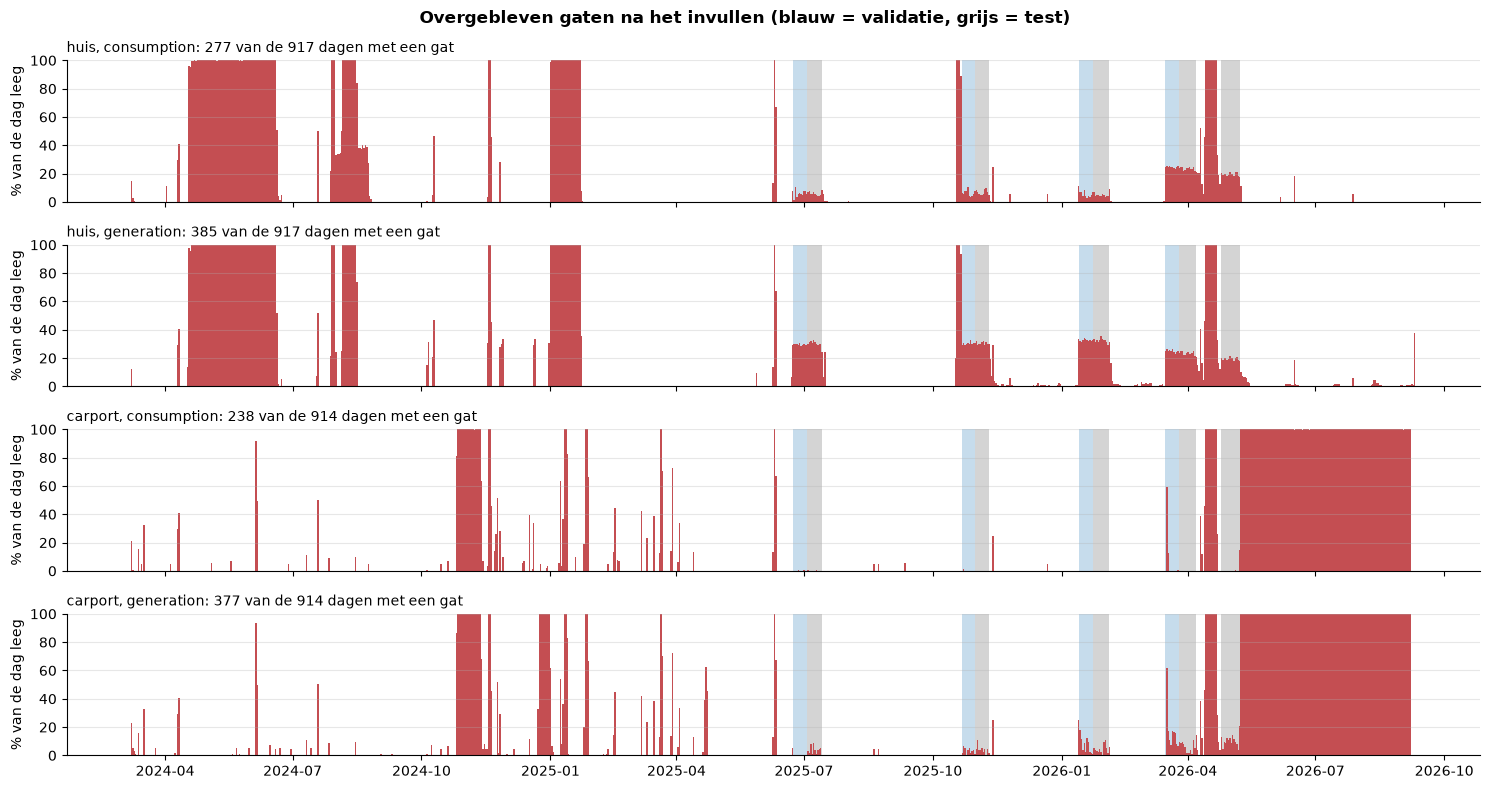

In [34]:
import matplotlib.pyplot as plt

per_dag = (targets_long.assign(leeg=targets_long["pow_imputed"].isna())
           .groupby(["location", "target_type", pd.Grouper(key="timestamp", freq="1D")])["leeg"].mean() * 100)

reeksen = [("huis", "consumption"), ("huis", "generation"), ("carport", "consumption"), ("carport", "generation")]

KLEUR_SET = {"val": "#1f77b4", "test": "#555555", "stresstest": "#555555"}

fig, assen = plt.subplots(len(reeksen), 1, figsize=(15, 8), sharex=True, sharey=True)

for ax, (locatie, target) in zip(assen, reeksen):
    dagen = per_dag.loc[(locatie, target)]

    for venster in vensters.itertuples():
        ax.axvspan(venster.start, venster.eind, color=KLEUR_SET[venster.set], alpha=0.25, lw=0)

    ax.bar(dagen.index, dagen.values, width=1, color="#c44e52")
    ax.set_title(f"{locatie}, {target}: {(dagen > 0).sum()} van de {len(dagen)} dagen met een gat",
                 fontsize=10, loc="left")
    ax.set_ylabel("% van de dag leeg")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Overgebleven gaten na het invullen (blauw = validatie, grijs = test)", fontweight="bold")
plt.tight_layout()
plt.show()

9.3 Controle nachtvulling

> Per uur van de dag: hoeveel punten bij de opwekking met 0 W gevuld zijn en hoeveel er nog leeg zijn. Validatie en test tellen bij "nog leeg" mee, daar wordt niets ingevuld
>
> De met 0 W gevulde punten horen bijna allemaal in de avond, nacht en vroege ochtend te vallen. Staan er veel midden op de dag, dan zijn de regels uit 4.5 te ruim
>
> Blijven er 's nachts nog veel punten leeg, dan voldoen die gaten niet aan de regels (bijvoorbeeld omdat ze aan een storing vastzitten)

In [35]:
opwekking = targets_long[targets_long["target_type"] == "generation"]

controle = pd.DataFrame({"met 0 W gevuld": opwekking["impute_methode"] == "nacht_nul",
                         "nog leeg": opwekking["pow_imputed"].isna()})

uur = opwekking["timestamp"].dt.hour.rename("uur")

controle.groupby([opwekking["location"], uur]).sum().unstack("location")

met 0 W gevuld       nog leeg      
location        carport  huis  carport  huis
uur                                         
0                   646  5424     2343  2392
1                  1183  5424     2424  2322
2                  1380  5412     2422  2352
3                  1453  5424     2404  2358
4                  1432  5423     2419  2347
5                   901  4657     2440  2148
6                   189  3290     2400  1877
7                    38  1518     2309  1724
8                    22   264     2261  1543
9                     6     0     2230  1496
10                    0     0     2213  1495
11                    0     0     2199  1471
12                    0     0     2205  1464
13                    0     0     2197  1465
14                    0     0     2149  1459
15                    0     0     2157  1455
16                    0    98     2149  1446
17                   12   673     2134  1627
18                   19  1142     2136  1735
19                   40  2121     2157  1841
20                   40  2954     2158  1940
21                   65  4050     2224  2044
22                  216  5219     2243  2275
23                  353  5424     2296  2370

9.4 Controle: staat de carport vanaf mei 2026 onder een andere naam?

> Beide carport-reeksen zijn vanaf mei 2026 maandenlang leeg (zie 9.2). Dat kan een echte storing zijn, maar ook een meter die vervangen of hernoemd is: stap 4 van het inladen filtert op één vaste `ENAME`
>
> De tabel telt per `ENAME` de rijen met een `POW` waarde, vóór en vanaf mei 2026. Duikt er vanaf mei een nieuwe naam op bij consumption of generation, dan staan de metingen daar en zijn ze terug te halen

In [36]:
vanaf = pd.Timestamp("2026-05-01", tz="Europe/Amsterdam")

met_pow = df_carport[df_carport["POW"].notna()]
kolommen = ["CTYPEC", "ETYPE", "ENAME"]

pd.DataFrame({"voor mei 2026": met_pow[met_pow["timestamp"] < vanaf].groupby(kolommen).size(),
              "vanaf mei 2026": met_pow[met_pow["timestamp"] >= vanaf].groupby(kolommen).size()}).fillna(0).astype(int)

voor mei 2026  \
CTYPEC      ETYPE      ENAME                                          
consumption powermeter totaalverbruik-e4393cd3dfdb           206122   
generation  solarpanel zonnepanelen-e4393cd3dfdb             178171   
storage     battery    victronaccu-e4393cd3dfdb              115362   
            powermeter victronaccu-e4393cd3dfdb                  44   
supply      powermeter hoofdaansluiting-e4393cd3dfdb         201589   

                                                      vanaf mei 2026  
CTYPEC      ETYPE      ENAME                                          
consumption powermeter totaalverbruik-e4393cd3dfdb              2264  
generation  solarpanel zonnepanelen-e4393cd3dfdb                2052  
storage     battery    victronaccu-e4393cd3dfdb                 2265  
            powermeter victronaccu-e4393cd3dfdb                    0  
supply      powermeter hoofdaansluiting-e4393cd3dfdb            2121

9.5 Dekking per venster

> Per venster en per reeks het percentage tijdstippen met een echte meting. Alleen op die tijdstippen kan een voorspelling gescoord worden
>
> Een venster met een lage dekking levert weinig scores op. Schuif het dan in 4.0 op naar een periode met minder gaten. Bij opwekking is een lagere dekking vóór oktober 2025 normaal: daar ontbreekt de nacht

In [37]:
buiten_train = targets_long[targets_long["set"] != "train"]

dekking = (buiten_train.groupby(["venster", "set", "location", "target_type"])["is_observed"].mean() * 100).round(1)

dekking.unstack(["location", "target_type"]).reindex(vensters.set_index(["venster", "set"]).index)

location                 carport                   huis           
target_type          consumption generation consumption generation
venster   set                                                     
zomer     val               99.9       99.4        94.0       70.3
          test              99.9       96.2        94.2       69.4
herfst    val               99.8       96.5        93.8       69.5
          test             100.0       95.9        93.0       69.4
winter    val              100.0       90.6        94.3       67.3
          test             100.0       95.9        95.2       67.4
lente     val               92.7       83.9        75.2       74.9
          test             100.0       94.3        76.6       76.7
na_uitval stresstest       100.0       90.2        80.4       80.4